*Ana Rosa Pérez y Albert Pineda*

## Proyecto APA Evaluación preliminar

# Predicción de Insuficiencia cardíaca crónica tras infarto de miocardio 

### Descripción del conjunto de datos y fuente

El conjunto de datos que hemos seleccionado es *Myocardial infarction complications* del UCI Machine Learning Repository (id 579): https://archive.ics.uci.edu/dataset/579/myocardial+infarction+complications

- **Contenido:** 1.700 pacientes ingresados con **infarto agudo de miocardio** en un hospital de Krasnoyarsk (Rusia), según la ficha del repositorio. Todos los pacientes han sufrido un infarto; la variable `INF_ANAM` recoge los infartos *previos*.
- **Atributos de entrada:** 111 variables de distinto tipo (demográficas, antecedentes, ECG al ingreso, analítica y tratamientos en urgencias/UCI). Hay variables binarias, ordinales codificadas como enteros y unas pocas continuas (edad, presión arterial, analítica).
- **Salidas:** 12 columnas con complicaciones o desenlaces posibles durante la hospitalización. Cada una de ellas podría ser una variable objetivo distinta.
- **Fuente de los datos:** datos clínicos de un único hospital, por lo que hay que ser prudentes al hablar de generalización a otros centros o a la práctica clínica actual.

Las complicaciones que nos indica la web del dataset junto al número de casos positivos son las siguientes:

| Variable objetivo | Complicación / desenlace | Casos negativos (0) | Casos positivos (1) | % positivos |
|---|---|---:|---:|---|
| FIBR_PREDS | Fibrilación auricular | 1530 | 170 | 10.00% |
| PREDS_TAH | Taquicardia supraventricular | 1680 | 20 | 1.18% | 
| JELUD_TAH | Taquicardia ventricular | 1658 | 42 | 2.47% | 
| FIBR_JELUD | Fibrilación ventricular | 1629 | 71 | 4.18% | 
| A_V_BLOK | Bloqueo AV de tercer grado | 1643 | 57 | 3.35% | 
| OTEK_LANC | Edema pulmonar | 1541 | 159 | 9.35% | 
| RAZRIV | Rotura miocárdica | 1646 | 54 | 3.18% | 
| DRESSLER | Síndrome de Dressler | 1625 | 75 | 4.41% | 
| ZSN | Insuficiencia cardíaca crónica | 1306 | 394 | 23.18% | 
| REC_IM | Recaída del infarto de miocardio | 1541 | 159 | 9.35% |
| P_IM_STEN | Angina posterior al infarto | 1552 | 148 | 8.71% | 
| LET_IS | Desenlace mortal (causa) | 1429* | 271* | 15.94%* |

(*) `LET_IS` es multiclase en el repositorio original (0 = sobrevive, 1–7 = causa de la muerte); la fila de la tabla corresponde a su binarización «sobrevive / fallece».

**Elección de la variable objetivo.** Elegimos la insuficiencia cardíaca crónica (`ZSN`) por los siguientes motivos:

1. Es la complicación con más casos positivos (394). Las demás tienen entre 20 y 271, y con tan pocos positivos cualquier métrica sobre un conjunto de test sería muy inestable.

2. Es una variable **binaria**, así que el problema es de **clasificación binaria**.

3. Tiene sentido clínico y de uso: identificar en el momento del ingreso a los pacientes con mayor riesgo de desarrollar insuficiencia cardíaca crónica permitiría reforzar su seguimiento.

**Problema:** *predecir si un paciente con infarto de miocardio desarrollará insuficiencia cardíaca crónica (`ZSN`) usando únicamente la información disponible en el momento del ingreso.*

#### Atributos asociados con el tiempo
En estos datos tenemos bastantes variables que tienen que ver con el tiempo y que pueden ser razonables o no para lo que nos interesa estudiar y en qué momento queremos predecir. Por ejemplo, no podemos utilizar una variable de *medicina dada el tercer dia tras el ingreso* si nuestro modelo predice en el día de ingreso. Las variables relacionadas al tiempo junto a su información temporal son:

| Variable | Significado | Tipo de información temporal |
|---|---|---|
| TIME_B_S | Tiempo transcurrido desde el inicio del episodio coronario hasta la llegada al hospital. | Tiempo previo al ingreso |
| STENOK_AN | Antecedentes de angina de esfuerzo y cuándo se produjeron. | Historial clínico |
| DLIT_AG | Duración de la hipertensión arterial. | Duración de una enfermedad previa |
| IBS_POST | Presencia y tipo de enfermedad coronaria en los días o semanas anteriores al ingreso. | Historial clínico reciente |
| R_AB_1_n | Número de recaídas del dolor durante las primeras horas de hospitalización. | Evolución hospitalaria inicial |
| R_AB_2_n | Número de recaídas del dolor durante el segundo día de hospitalización. | Evolución hospitalaria, día 2 |
| R_AB_3_n | Número de recaídas del dolor durante el tercer día de hospitalización. | Evolución hospitalaria, día 3 |
| NA_R_1_n | Uso de opioides en la unidad de cuidados intensivos durante las primeras horas. | Tratamiento hospitalario inicial |
| NA_R_2_n | Uso de opioides en la unidad de cuidados intensivos durante el segundo día. | Tratamiento hospitalario, día 2 |
| NA_R_3_n | Uso de opioides en la unidad de cuidados intensivos durante el tercer día. | Tratamiento hospitalario, día 3 |
| NOT_NA_1_n | Uso de antiinflamatorios no esteroideos durante las primeras horas en cuidados intensivos. | Tratamiento hospitalario inicial |
| NOT_NA_2_n | Uso de antiinflamatorios no esteroideos durante el segundo día en cuidados intensivos. | Tratamiento hospitalario, día 2 |
| NOT_NA_3_n | Uso de antiinflamatorios no esteroideos durante el tercer día en cuidados intensivos. | Tratamiento hospitalario, día 3 |

Consideramos que es más útil realizar un predictor utilizado en el **momento del ingreso**, es por eso que eliminamos las variables de evolución y tratamiento posteriores al ingreso (`R_AB_1_n`, `R_AB_2_n`, `R_AB_3_n`, `NA_R_1_n`, `NA_R_2_n`, `NA_R_3_n`, `NOT_NA_1_n`, `NOT_NA_2_n`, `NOT_NA_3_n`), que se corresponden con las columnas 93-95 y 100-105 del fichero original. Estas son exactamente las que la documentación del repositorio excluye para predecir al ingreso, ya que describen algo que aún no habría ocurrido.


#### Desbalance entre clases

La variable objetivo `ZSN` representa la presencia o ausencia de insuficiencia cardíaca crónica.

Según la distribución del dataset, hay 394 pacientes positivos y 1.306 negativos, sobre un total de 1.700 pacientes:

| Clase | Significado | Número de pacientes | Porcentaje |
|---|---|---:|---:|
| 0 | Sin insuficiencia cardíaca crónica | 1.306 | 76,82 % |
| 1 | Con insuficiencia cardíaca crónica | 394 | 23,18 % |
| **Total** | | **1.700** | **100 %** |

Existe, por tanto, un desbalance moderado entre las clases. No es un desequilibrio extremo, pero sí suficientemente importante como para tenerlo en cuenta al entrenar y evaluar el modelo. El riesgo es que el modelo se limite a predecir casi siempre la clase mayoritaria («sin ZSN»). En este caso obtendría una *accuracy* alta (≈ 76,8 %, la proporción de la clase mayoritaria) sin detectar apenas casos de insuficiencia cardíaca crónica. Por eso la accuracy no es una métrica adecuada por sí sola. Usaremos además  la *precission* y la *recall*.

Durante el preprocesamiento se conservará la distribución de clases y se utilizará una partición estratificada para mantener proporciones similares de ambas clases en los conjuntos de entrenamiento y prueba. Si fuera necesario aplicar técnicas de sobremuestreo o submuestreo, estas se realizarán únicamente sobre los datos de entrenamiento.

Además vemos que el conjunto presenta en casi todas las variables valores perdidos. Descartar los pacientes con algún dato ausente reduciría drásticamente el conjunto, así que habrá que imputar los valores y/o descartar las variables casi vacías.

In [1]:
import pandas as pd
from pandas import read_csv

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score

from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn import set_config

from sklearn.metrics import  ConfusionMatrixDisplay,\
                  classification_report,  RocCurveDisplay, PrecisionRecallDisplay,\
                    accuracy_score, f1_score, precision_score, recall_score

from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB, GaussianNB, CategoricalNB, MultinomialNB

from sklearn.model_selection import GridSearchCV

from yellowbrick.target.feature_correlation import feature_correlation
from yellowbrick.classifier import precision_recall_curve

import warnings

plt.rcParams['font.family'] = 'DejaVu Sans'

set_config(display='text')
warnings.filterwarnings('ignore')
plt.rcParams.update({'font.size': 16})
pd.set_option('display.precision', 3)

In [2]:
def save_results(clf, X_test, y_test, nclf, df):
    if hasattr(clf, 'best_score_'):
        df.loc[nclf,'train XV acc'] = clf.best_score_
    else:
        df.loc[nclf,'train XV acc'] = np.nan
    df.loc[nclf,'test acc'] = accuracy_score(y_test, clf.predict(X_test))
    df.loc[nclf,'precision score (M)'] = precision_score(y_test, clf.predict(X_test), average='macro')
    df.loc[nclf,'recall score (M)'] = recall_score(y_test, clf.predict(X_test), average='macro')
    df.loc[nclf,'f1 score (M)'] = f1_score(y_test, clf.predict(X_test), average='macro')
    return df

results_df = pd.DataFrame()

niter = 15
cv = 5

### Obtención de los datos

Utilizamos la función de importación proporcionada por el repositorio de UC Irvine

In [3]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Cargar dataset
myocardial_infarction_complications = fetch_ucirepo(id=579)

X = myocardial_infarction_complications.data.features
y = myocardial_infarction_complications.data.targets

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

display(X.head())
display(y.head())

Dimensiones de X: (1700, 111)
Dimensiones de y: (1700, 12)


,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,IBS_NASL,GB,SIM_GIPERT,DLIT_AG,...,NOT_NA_1_n,NOT_NA_2_n,NOT_NA_3_n,LID_S_n,B_BLOK_S_n,ANT_CA_S_n,GEPAR_S_n,ASP_S_n,TIKL_S_n,TRENT_S_n
0,77.0,1,2.0,1.0,1.0,2.0,NaN,3.0,0.0,7.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
1,55.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0
2,52.0,1,0.0,0.0,0.0,2.0,NaN,2.0,0.0,2.0,...,3.0,2.0,2.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0
3,68.0,0,0.0,0.0,0.0,2.0,NaN,2.0,0.0,3.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0
4,60.0,1,0.0,0.0,0.0,2.0,NaN,3.0,0.0,7.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


,FIBR_PREDS,PREDS_TAH,JELUD_TAH,FIBR_JELUD,A_V_BLOK,OTEK_LANC,RAZRIV,DRESSLER,ZSN,REC_IM,P_IM_STEN,LET_IS
0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,1,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0


In [5]:
TARGET = "ZSN"
df = X.copy().reset_index(drop=True)

# Añadir el target al DataFrame auxiliar
df[TARGET] = pd.to_numeric(
    y[TARGET].reset_index(drop=True),
    errors="coerce"
)

# Eliminar el identificador: no tiene significado clínico predictivo
df = df.drop(columns=["ID"], errors="ignore")

# Revisar la distribución del target
print("Distribución de ZSN:")
display(
    df[TARGET]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("ZSN")
    .to_frame("Número de pacientes")
)

print("\nValores ausentes en ZSN:", df[TARGET].isna().sum())

Distribución de ZSN:


,Número de pacientes
ZSN,
0,1306
1,394



Valores ausentes en ZSN: 0


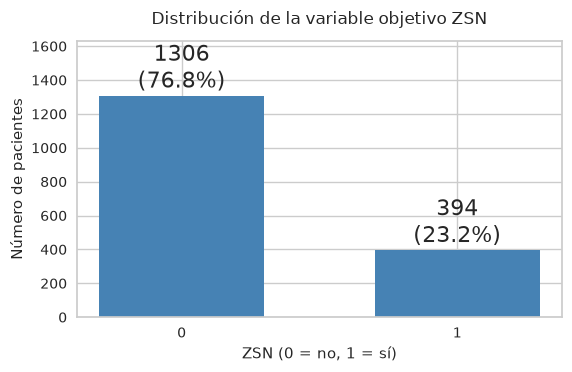

In [6]:
counts = df[TARGET].value_counts().sort_index()
percentages = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(counts.index.astype(str), counts.values,
              color='steelblue', width=0.6)

ax.set_title("Distribución de la variable objetivo ZSN", pad=12)
ax.set_xlabel("ZSN (0 = no, 1 = sí)")
ax.set_ylabel("Número de pacientes")
ax.set_ylim(0, max(counts.values) * 1.25)

for bar, count, percentage in zip(bars, counts.values, percentages.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            f"{count}\n({percentage:.1f}%)",
            ha="center", va="bottom")

plt.tight_layout()
plt.show()

Según la documentación del repositorio, para predecir en el momento del ingreso (nuestro caso) hay que eliminar las columnas 93, 94, 95, 100, 101, 102, 103, 104 y 105 del fichero original, pues contienen información futura respecto al momento de la predicción y provocarían *data leakage*. En el código identificamos esas columnas por nombre y comprobamos con un `assert` que coinciden con las posiciones indicadas en la documentación, para no depender del orden de las columnas.

El resultado son 102 variables de entrada. Las exploraciones de esta sección se hacen sobre todos los pacientes porque son puramente descriptivas y no se usan para seleccionar variables del modelo.

In [7]:
# Variables que contienen información posterior al ingreso (columnas 93-95 y 100-105 del fichero original)
EXCLUIDAS_INGRESO = [
    "R_AB_1_n", "R_AB_2_n", "R_AB_3_n",
    "NA_R_1_n", "NA_R_2_n", "NA_R_3_n",
    "NOT_NA_1_n", "NOT_NA_2_n", "NOT_NA_3_n",
]

# Comprobación: coinciden con las posiciones de la documentación (X no incluye ID, por eso pos = col - 2)
posiciones_doc = [93, 94, 95, 100, 101, 102, 103, 104, 105]
assert [X.columns[p - 2] for p in posiciones_doc] == EXCLUIDAS_INGRESO, \
    "Las columnas excluidas no coinciden con la documentación"

feature_cols = [c for c in X.columns if c not in EXCLUIDAS_INGRESO]
print("Número de variables permitidas:", len(feature_cols))

# DataFrame de exploración: variables permitidas en formato numérico + objetivo
df_visual = X[feature_cols].apply(pd.to_numeric, errors="coerce").reset_index(drop=True)
df_visual[TARGET] = pd.to_numeric(y[TARGET].reset_index(drop=True), errors="coerce")

Número de variables permitidas: 102


### Valores ausentes

Porcentaje medio de valores ausentes por variable: 8.8 %
Variables sin ningún valor ausente: 1 de 102
Variables con más de  5 % de ausentes: 46
Variables con más de 20 % de ausentes: 11
Variables con más de 50 % de ausentes: 4
Variables con más de 90 % de ausentes: 2
Pacientes con al menos un dato ausente: 100.0 %


,% ausentes
KFK_BLOOD,99.765
IBS_NASL,95.765
S_AD_KBRIG,63.294
D_AD_KBRIG,63.294
NOT_NA_KB,40.353
LID_KB,39.824
NA_KB,38.647
NA_BLOOD,22.059
GIPER_NA,22.059
K_BLOOD,21.824


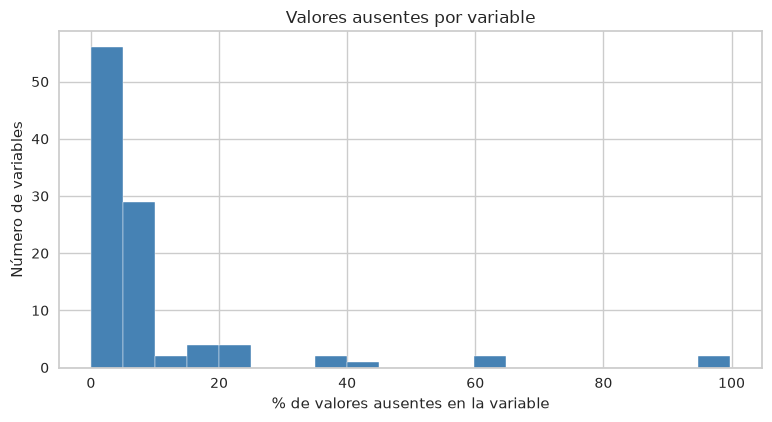

In [8]:
pct_nulos = (df_visual[feature_cols].isna().mean() * 100).sort_values(ascending=False)

print(f"Porcentaje medio de valores ausentes por variable: {pct_nulos.mean():.1f} %")
print(f"Variables sin ningún valor ausente: {(pct_nulos == 0).sum()} de {len(pct_nulos)}")
for umbral in (5, 20, 50, 90):
    print(f"Variables con más de {umbral:>2} % de ausentes: {(pct_nulos > umbral).sum()}")
print(f"Pacientes con al menos un dato ausente: "
      f"{df_visual[feature_cols].isna().any(axis=1).mean() * 100:.1f} %")

display(pct_nulos[pct_nulos > 20].rename("% ausentes").to_frame())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(pct_nulos, bins=20, color="steelblue", edgecolor="white")
ax.set_xlabel("% de valores ausentes en la variable")
ax.set_ylabel("Número de variables")
ax.set_title("Valores ausentes por variable")
plt.tight_layout()
plt.show()

Observamos qeu hay variables con más del 90 % de valores ausentes. Estas variables aportan poca información y cualquier estadístico calculado con los pocos pacientes que sí la tienen es poco fiable.

### Visualización de variables frente al objetivo

#### Selección de variables a visualizar

Dado que el número de variables es muy elevado, para hacer una visualización inicial de los datos, escogemos las variables más correladas con la variable objetivo. Sin embargo, también se tiene en cuenta la proporción de valores ausentes de dichas variables para considerar si su posición en el ranking es fiable.

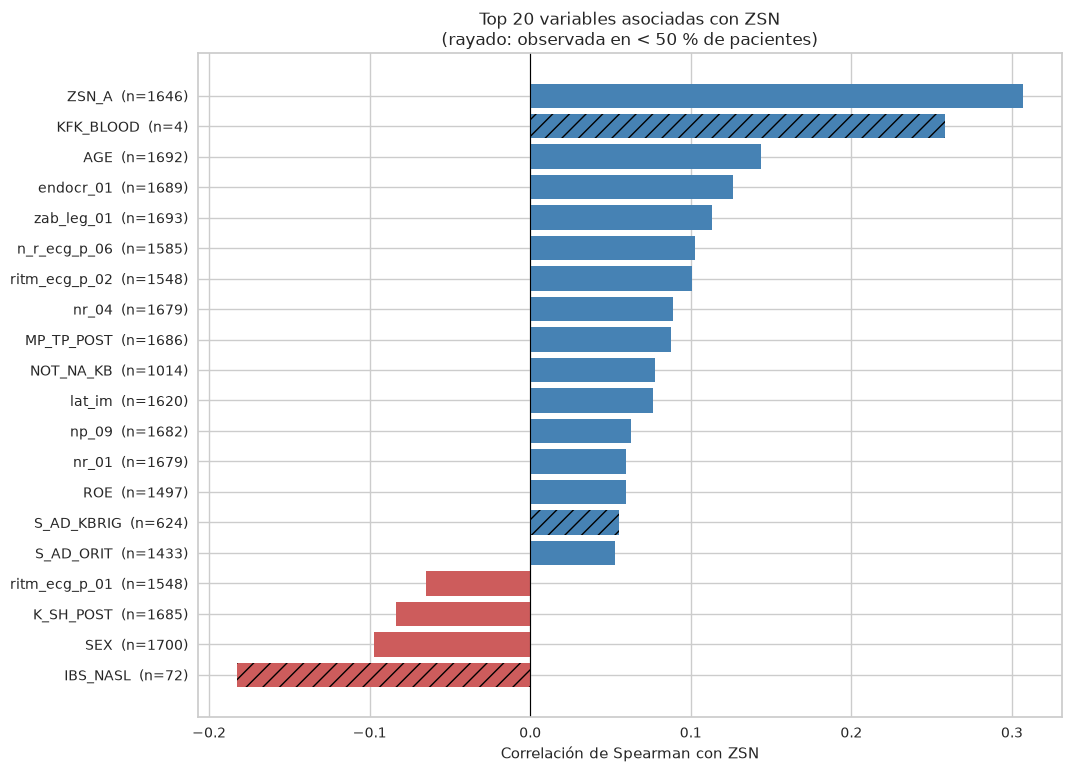

,rho Spearman,|rho|,n_obs,% ausentes
ZSN_A,0.307,0.307,1646,3.176
KFK_BLOOD,0.258,0.258,4,99.765
IBS_NASL,-0.183,0.183,72,95.765
AGE,0.144,0.144,1692,0.471
endocr_01,0.126,0.126,1689,0.647
zab_leg_01,0.113,0.113,1693,0.412
n_r_ecg_p_06,0.103,0.103,1585,6.765
ritm_ecg_p_02,0.101,0.101,1548,8.941
SEX,-0.097,0.097,1700,0.000
nr_04,0.089,0.089,1679,1.235


In [9]:
n_obs = df_visual[feature_cols].notna().sum()
N = len(df_visual)

corr_target = (
    df_visual[feature_cols + [TARGET]]
    .corr(method="spearman")[TARGET]
    .drop(TARGET)
    .dropna()
)
corr_target = corr_target.reindex(corr_target.abs().sort_values(ascending=False).index)

tabla_corr = pd.DataFrame({
    "rho Spearman": corr_target,
    "|rho|": corr_target.abs(),
    "n_obs": n_obs[corr_target.index],
    "% ausentes": pct_nulos[corr_target.index],
})

top_n = min(20, len(corr_target))
top_corr = corr_target.head(top_n).sort_values()

plt.figure(figsize=(11, max(6, top_n * 0.4)))
colors = ["steelblue" if v >= 0 else "indianred" for v in top_corr.values]
barras = plt.barh([f"{v}  (n={n_obs[v]})" for v in top_corr.index], top_corr.values, color=colors)
for barra, var in zip(barras, top_corr.index):
    if n_obs[var] < 0.5 * N:          # variable observada en menos de la mitad de los pacientes
        barra.set_hatch("//")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlación de Spearman con ZSN")
plt.title(f"Top {top_n} variables asociadas con ZSN\n(rayado: observada en < 50 % de pacientes)")
plt.tight_layout()
plt.show()

display(tabla_corr.head(20))

Utilizamos la correlación de Spearman ya que consideramos que una lineal como la de Pearson no es muy útil en datos de estudio clínico de muchos tipos con seguramente varias relaciones no lineales. Aún así, es importante destacar que hay algunas variables categóricas codificadas en números y aquí Pearson no lo hace tan bien, por eso, esta visualización es importante verla con precaución.

**Variables más asociadas**

- `ZSN_A` (0,307) recoge los antecedentes de insuficiencia cardíaca crónica. Es la más asociada a la variable objetivo, cosa que es coherente, puesto que ambas variables describen la misma condición clínica, antes del ingreso y durante la hospitalización. Es legítima como predictor al ingreso, pero es la que más peso tendrá en cualquier modelo.
- `KFK_BLOOD` (0,258), concentración de creatina fosfoquinasa en sangre (marcador de daño miocárdico), e `IBS_NASL` (−0,183), antecedentes familiares de cardiopatía isquémica. Aunque aparecen entre las primera, se han medido con muy pocos pacientes y tienen un porcentaje de nulos que supera el 95%, por lo que consideramos que no proporcionan información fiable.
- `AGE` (0,144) y `endocr_01` (0,126, antecedentes de diabetes) muestran una asociación positiva débil: más edad y diabetes se relacionan con más insuficiencia cardíaca crónica, en línea con lo esperable clínicamente.

En conjunto las asociaciones individuales son débiles, puesto que ninguna supera 0,31. Así pues, no hay una variable que por sí sola resuelva el problema, lo que es una señal de que el conjunto no es trivial.

#### Gráficas

Para las variables más asociadas con `ZSN` y observadas en al menos la mitad de los pacientes, mostramos su relación directa con el objetivo, incluyendo también los valores ausentes.

Hemos escogido el umbral en 50% de valores ausentes porque en general se considera que a partir de este valor, la variable pierde su fiabilidad estadística y así descartamos correlaciones apoyadas en pocos datos.

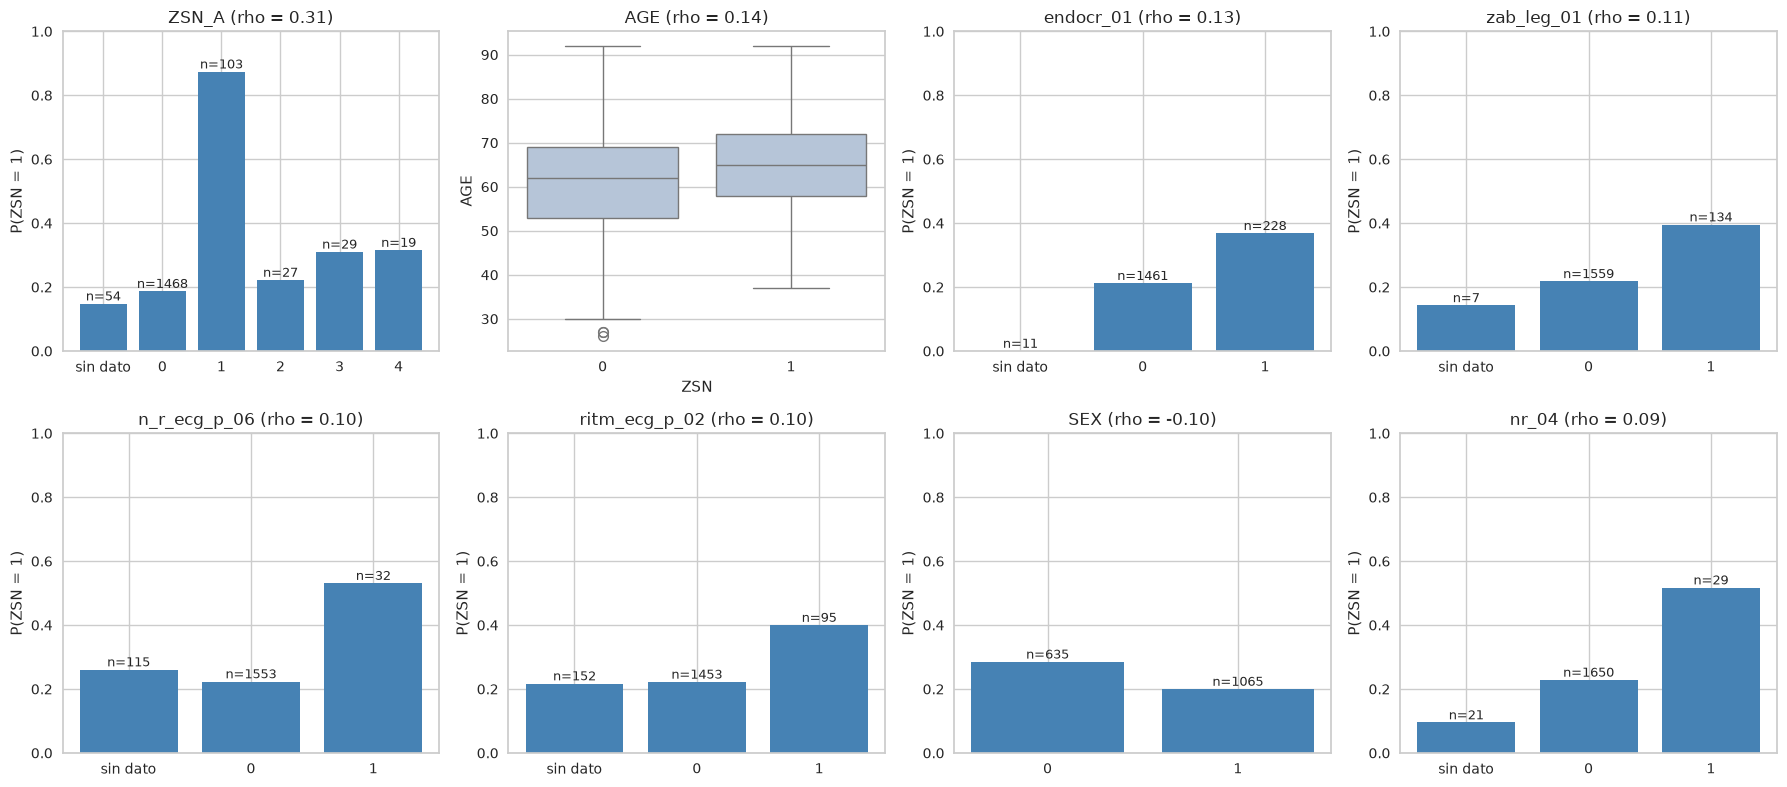

In [10]:
fiables = tabla_corr[tabla_corr["n_obs"] >= 0.5 * N].head(8).index.tolist()

with plt.rc_context({"font.size": 11}):
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax, col in zip(axes.ravel(), fiables):
        s = df_visual[col]
        if s.nunique() <= 10:
            # Variable discreta: proporción de ZSN en cada categoría (-1 = sin dato)
            tmp = (pd.DataFrame({"v": s.fillna(-1), "y": df_visual[TARGET]})
                   .groupby("v")["y"].agg(["mean", "size"]))
            etiquetas = ["sin dato" if v == -1 else f"{v:g}" for v in tmp.index]
            ax.bar(etiquetas, tmp["mean"], color="steelblue")
            for i, (m, n) in enumerate(zip(tmp["mean"], tmp["size"])):
                ax.text(i, m + 0.01, f"n={n}", ha="center", fontsize=9)
            ax.set_ylim(0, 1)
            ax.set_ylabel("P(ZSN = 1)")
        else:
            # Variable continua: distribución por clase
            sns.boxplot(data=df_visual, x=TARGET, y=col, ax=ax, color="lightsteelblue")
            ax.set_xlabel("ZSN")
        ax.set_title(f"{col} (rho = {corr_target[col]:.2f})")
    for ax in axes.ravel()[len(fiables):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### Matriz de correlación

La matriz completa de correlaciones no aporta mucha información puesto que no se puede leer con detalle. Sin embargo, sí que sirve para ver la estructura global de los datos.

Para poder tener una idea más clara de las correlaciones entre las variables, observamos la correlación entre las 20 variables con mayor asociación a la variable objetivo.

En este caso no se ha considerado el porcentaje de valores ausentes para simplificar el análisis, pero en análisis posteriores más complejos sí que se tendrá en cuenta.

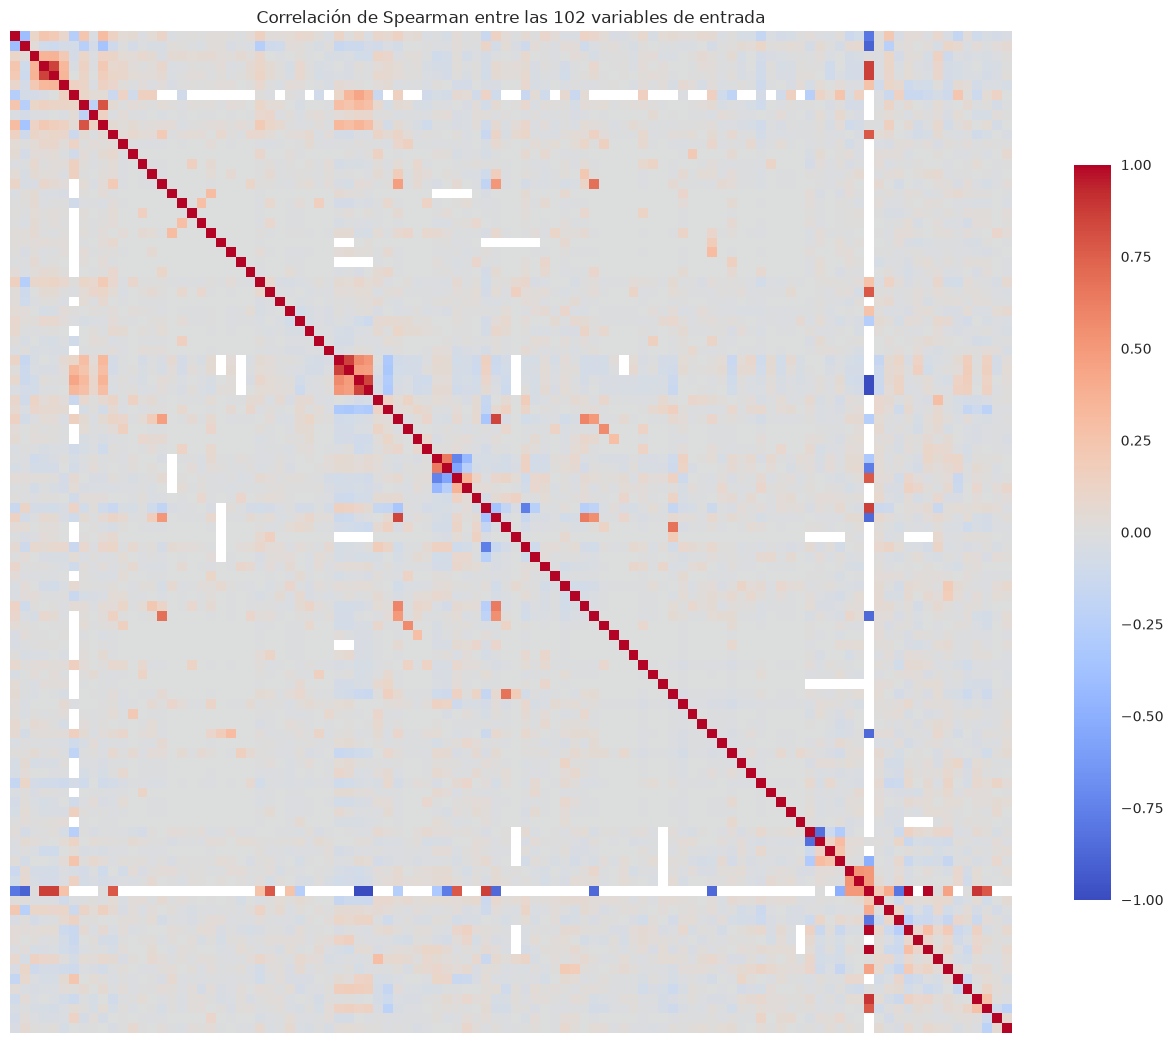

In [11]:
corr_full = df_visual[feature_cols].corr(method="spearman")

plt.figure(figsize=(13, 11))
sns.heatmap(corr_full, cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True,
            xticklabels=False, yticklabels=False, cbar_kws={"shrink": 0.7})
plt.title("Correlación de Spearman entre las 102 variables de entrada")
plt.tight_layout()
plt.show()

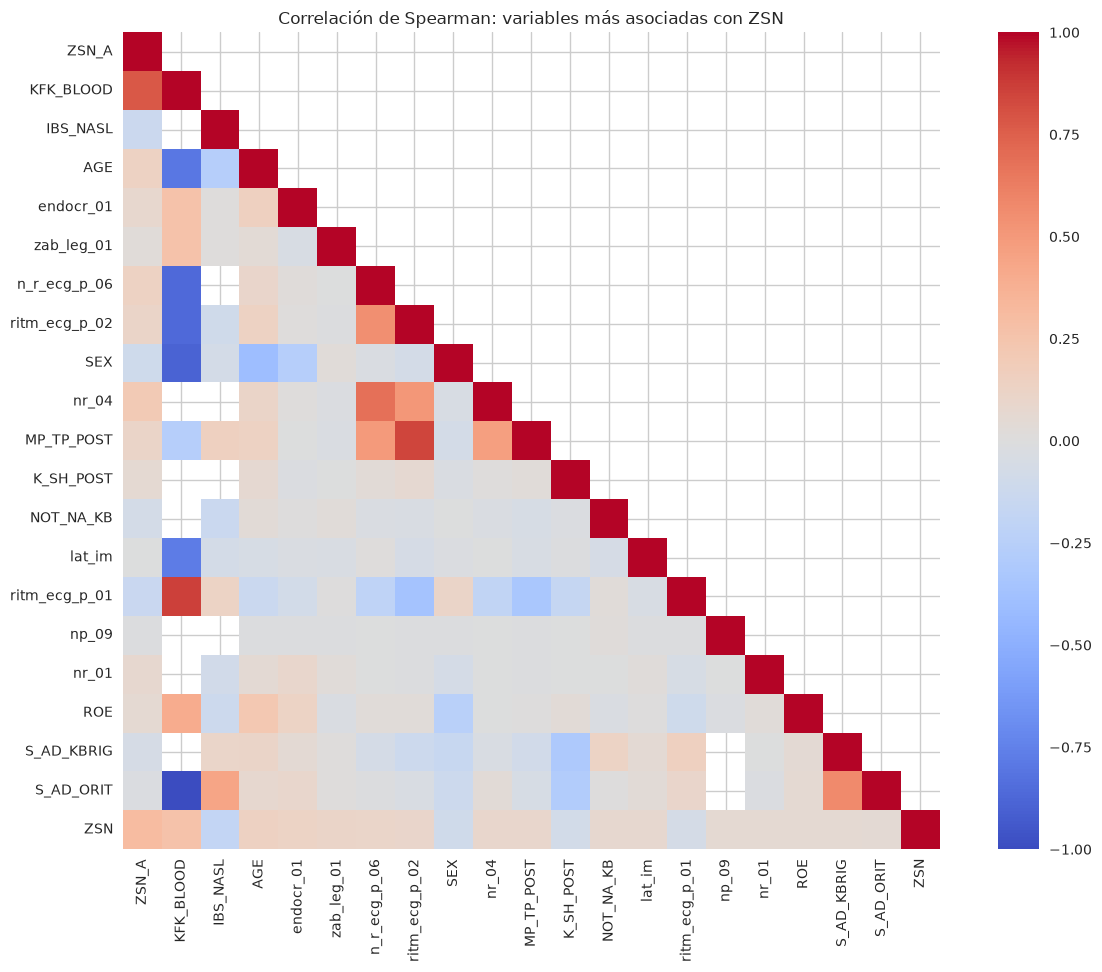

In [12]:

# Seleccionar las 20 variables con mayor asociación absoluta con ZSN.
top_features = corr_target.head(
    min(20, len(corr_target))
).index.tolist()

# Matriz de correlación entre las variables seleccionadas y el target.
corr_matrix = df_visual[top_features + [TARGET]].corr(
    method="spearman"
)

# Mostrar la mitad inferior de la matriz.
mask = np.triu(
    np.ones_like(corr_matrix, dtype=bool),
    k=1
)

plt.figure(figsize=(13, 10))

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title(
    "Correlación de Spearman: variables más asociadas con ZSN"
)
plt.tight_layout()
plt.show()


## Preprocesado de referencia simple

Para obtener unos resultados de referencia implementaremos un modelo simple junto con un preprocesado sencillo de los datos. 

El preprocesado consistirá en la imputación de los valores ausentes con la mediana para las variables continuas y la moda para las categóricas. 

En cuanto al modelo, implementaremos un Naive Bayes categórico, discretizando las variables continuas en 5 intervalos por cuantiles. Esto lo hacemos porque la mayoría de las variables son categóricas y discretizar las continuas simplifica el análisis, puesto que así no se tienen que mezclar modelos.

### Partición entrenamiento / test y preproceso sencillo

Hacemos una partición estratificada 70 % / 30 % para que el balance de positivos y negativos quede igual en ambos conjuntos.

In [13]:

valid = y[TARGET].notna()

X_model = X.loc[valid, feature_cols].copy()
y_model = y.loc[valid, TARGET].astype(int).copy()


X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.30,
    random_state=42,
    stratify=y_model
)

print("Variables seleccionadas:", len(feature_cols))
print("Train:", X_train.shape)
print("Test:", X_test.shape)


Variables seleccionadas: 102
Train: (1190, 102)
Test: (510, 102)


### Imputación de valores ausentes

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import KBinsDiscretizer

continuous_cols = [
    col for col in [
        "AGE", "S_AD_KBRIG", "D_AD_KBRIG",
        "S_AD_ORIT", "D_AD_ORIT",
        "K_BLOOD", "NA_BLOOD", "ALT_BLOOD",
        "AST_BLOOD", "KFK_BLOOD", "L_BLOOD", "ROE"
    ]
    if col in X_train.columns
]

categorical_cols = [
    col for col in X_train.columns
    if col not in continuous_cols
]

for col in X_train.columns:
    X_train[col] = pd.to_numeric(X_train[col], errors="coerce")
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce")

imp_cont = SimpleImputer(strategy="median")
imp_cat = SimpleImputer(strategy="most_frequent")

train_cont = pd.DataFrame(
    imp_cont.fit_transform(X_train[continuous_cols]),
    columns=continuous_cols, index=X_train.index
)
test_cont = pd.DataFrame(
    imp_cont.transform(X_test[continuous_cols]),
    columns=continuous_cols, index=X_test.index
)

train_cat = pd.DataFrame(
    imp_cat.fit_transform(X_train[categorical_cols]),
    columns=categorical_cols, index=X_train.index
)
test_cat = pd.DataFrame(
    imp_cat.transform(X_test[categorical_cols]),
    columns=categorical_cols, index=X_test.index
)

Separamos las variables continuas de las categóricas para aplicar una estrategia de imputación adecuada a cada tipo. Las variables continuas se imputan con la mediana, que es menos sensible a valores extremos, mientras que las categóricas se imputan con la moda, es decir, el valor más frecuente. La moda/mediana en columnas con muchísimos nulos las convierte casi en constantes pero usamos este método como estrategia preliminar.

In [ ]:
disc = KBinsDiscretizer(
    n_bins=5,
    encode="ordinal",
    strategy="quantile",
    subsample=None
)

train_cont = pd.DataFrame(
    disc.fit_transform(train_cont),
    columns=continuous_cols, index=X_train.index
).astype(int)

test_cont = pd.DataFrame(
    disc.transform(test_cont),
    columns=continuous_cols, index=X_test.index
).astype(int)

Se utiliza KBinsDiscretizer para transformar las variables continuas en cinco intervalos según sus cuantiles. Así, los valores numéricos se convierten en categorías representadas por enteros del 0 al 4, facilitando su uso con CategoricalNB. Los límites de los intervalos se calculan únicamente con el conjunto de entrenamiento y se aplican después al conjunto de test.

In [16]:
X_train_nb = pd.concat([train_cont, train_cat], axis=1)
X_test_nb = pd.concat([test_cont, test_cat], axis=1)

for col in categorical_cols:
    X_train_nb[col] = X_train_nb[col].astype(int)
    X_test_nb[col] = X_test_nb[col].astype(int)

X_test_nb = X_test_nb[X_train_nb.columns]

print("Valores ausentes en train:", X_train_nb.isna().sum().sum())
print("Valores ausentes en test:", X_test_nb.isna().sum().sum())


Valores ausentes en train: 0
Valores ausentes en test: 0


En este bloque se unen las variables continuas discretizadas con las categóricas imputadas para reconstruir los conjuntos de entrenamiento y test

In [17]:
min_cats = np.maximum(X_train_nb.max().values, X_test_nb.max().values) + 1

model_cat = CategoricalNB(alpha=1.0, min_categories=min_cats)
model_cat.fit(X_train_nb, y_train)
y_pred_cat = model_cat.predict(X_test_nb)
print("Accuracy:", round(model_cat.score(X_test_nb, y_test), 4))

Accuracy: 0.7804


              precision    recall  f1-score   support

     Sin ZSN       0.83      0.90      0.86       392
     Con ZSN       0.54      0.37      0.44       118

    accuracy                           0.78       510
   macro avg       0.68      0.64      0.65       510
weighted avg       0.76      0.78      0.77       510

ROC AUC: 0.6985
Balanced acc: 0.638


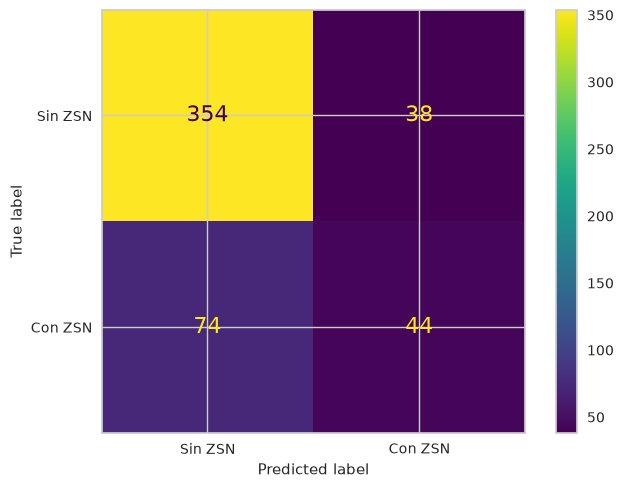

In [18]:
from sklearn.metrics import classification_report, roc_auc_score, balanced_accuracy_score

print(classification_report(y_test, y_pred_cat, target_names=["Sin ZSN", "Con ZSN"]))
print("ROC AUC:", round(roc_auc_score(y_test, model_cat.predict_proba(X_test_nb)[:, 1]), 4))
print("Balanced acc:", round(balanced_accuracy_score(y_test, y_pred_cat), 4))

ConfusionMatrixDisplay.from_estimator(model_cat, X_test_nb, y_test,
                                      display_labels=["Sin ZSN", "Con ZSN"])

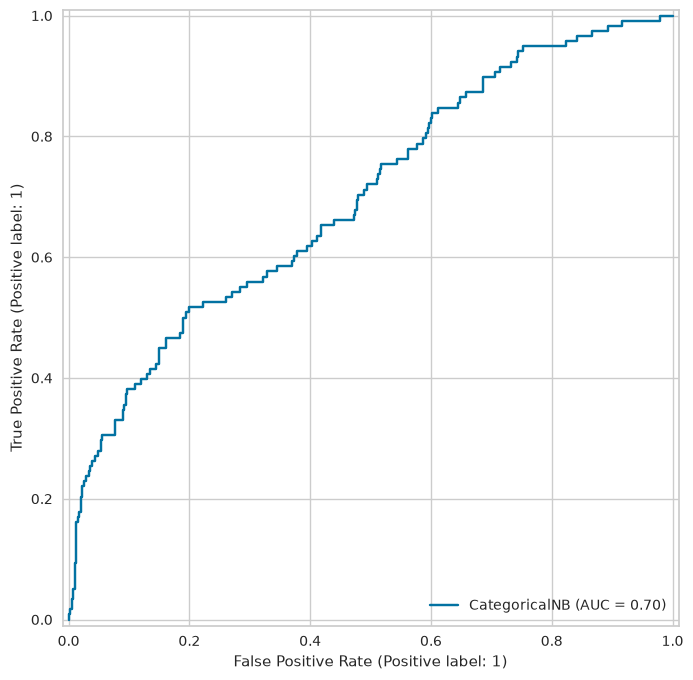

In [19]:
plt.figure(figsize=(8,8))
RocCurveDisplay.from_estimator(model_cat, X_test_nb, y_test,
                               pos_label=1, ax=plt.subplot())

Usando un Categorical Naive Byes vemos que con un 76,9 % de pacientes sin ZSN, predecir siempre «Sin ZSN» (modelo trivial) daría una *accuracy* del 0.769, así que 0.78 es prácticamente la línea base. Así pues, la *accuracy* no distingue este modelo del trivial.

El modelo detecta solo el 37% de los casos de ZSN (44 de 118) y predice 74 falsos negativos, lo cual es el principal problema, pues clínicamente es el error más costoso. Por otro lado, descarta bien a los sanos. Acierta 354 de 392 pacientes sin ZSN (especificidad ≈ 90 %). Casi todo el acierto del modelo viene de la clase mayoritaria.

No obstante, el ROC AUC es 0.7, lo cual está claramente por encima del 0.5 de un clasificador sin información.

## Conclusión de evaluación inicial
Con las variables disponibles, el Naive Bayes categórico alcanza en test ROC AUC 0,70 y balanced accuracy 0,64, con una accuracy (0,78) casi igual a la del clasificador trivial (0,77), una precisión de 0,54 y un recall de solo 0,37 para la clase positiva. 

El Naive Bayes de referencia (AUC 0,70, recall 0,37) descarta que el problema sea demasiado fácil, pues un modelo simple no lo resuelve, y las correlaciones entre las variables son débiles (|ρ| ≤ 0,31). El AUC claramente superior a 0,5 indica además que hay información predictiva, por lo que tampoco es inabordable. Por tanto, con los resultados obtenidos consideramos que el problema no es trivial y tiene margen de mejora.